In [ ]:
Create customer-level features such as recency, frequency, monetary value, 
average order value, purchase trend, and customer tenure. 
Define churn operationally and document the prediction window.

In [2]:
import pandas as pd
import numpy as np
print("library loaded succesfully")

library loaded succesfully


In [4]:
file =r"C:\Users\RSC\Desktop\data sheets\project\data science project\customers.csv"
df = pd.read_csv(file)
df.head()

,CustomerID,Age,Gender,Country,City,SignupDate,Churned,ChurnDefinition,SnapshotDate
0,C00001,37,Female,India,Hyderabad,2023-06-20,0,1 = no purchase in label window; 0 = at least ...,2025-01-01
1,C00002,42,Male,United Kingdom,Manchester,2023-09-15,0,1 = no purchase in label window; 0 = at least ...,2025-01-01
2,C00003,44,Male,United Kingdom,Manchester,2023-10-14,1,1 = no purchase in label window; 0 = at least ...,2025-01-01
3,C00004,51,Female,India,Chennai,2023-05-06,1,1 = no purchase in label window; 0 = at least ...,2025-01-01
4,C00005,56,Male,India,Hyderabad,2023-02-21,0,1 = no purchase in label window; 0 = at least ...,2025-01-01


In [5]:
file1=r"C:\Users\RSC\Desktop\data sheets\project\data science project\products.csv"
df1 = pd.read_csv(file1)
df1.head()

,ProductID,ProductName,Category,UnitPrice
0,P1001,Wireless Mouse,Electronics,93.55
1,P1002,USB-C Cable,Electronics,54.35
2,P1003,Bluetooth Speaker,Electronics,103.46
3,P1004,Power Bank,Electronics,84.59
4,P1005,Keyboard,Electronics,14.02


In [6]:
file2 = r"C:\Users\RSC\Desktop\data sheets\project\data science project\transaction.csv"
df2 = pd.read_csv(file2)
df2.head()

,InvoiceNo,CustomerID,ProductID,Quantity,UnitPrice,InvoiceDate,LineRevenue
0,INV500001,C00001,P1002,1,54.35,06-07-2024,54.35
1,INV500001,C00001,P1012,2,111.43,06-07-2024,222.86
2,INV500002,C00001,P1018,2,10.47,23-07-2024,20.94
3,INV500003,C00001,P1006,3,117.15,10-09-2024,351.45
4,INV500004,C00001,P1022,3,44.48,31-10-2024,133.44


In [7]:
file3=r"C:\Users\RSC\Desktop\data sheets\project\data science project\customer_features.csv"
df3 = pd.read_csv(file3)
df3

,CustomerID,Age,Gender,Country,City,SignupDate,HistoricalOrders,HistoricalItems,HistoricalSpend,LastPurchaseDate,FirstPurchaseDate,RecencyDaysAtCutoff,CustomerTenureDaysAtCutoff,AverageOrderValue
0,C00001,37,Female,India,Hyderabad,2023-06-20,3,8,649.60,2024-09-10,2024-07-06,21,87,216.53
1,C00002,42,Male,United Kingdom,Manchester,2023-09-15,5,29,2480.96,2024-06-05,2024-01-11,118,264,496.19
2,C00003,44,Male,United Kingdom,Manchester,2023-10-14,4,18,1457.88,2024-08-11,2024-02-15,51,229,364.47
3,C00004,51,Female,India,Chennai,2023-05-06,4,24,1580.50,2024-09-21,2024-04-10,10,174,395.12
4,C00005,56,Male,India,Hyderabad,2023-02-21,2,5,82.01,2024-06-27,2024-06-21,96,102,41.00
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
795,C00796,41,Male,India,Hyderabad,2023-09-08,3,19,947.24,2024-09-23,2024-04-17,8,167,315.75
796,C00797,23,Male,India,Pune,2023-09-26,6,22,1189.81,2024-07-23,2024-01-07,70,268,198.30
797,C00798,47,Female,Australia,Sydney,2023-07-14,8,34,2941.73,2024-09-05,2024-01-25,26,250,367.72
798,C00799,59,Female,United Kingdom,London,2023-04-29,3,23,1753.25,2024-06-03,2024-03-02,120,213,584.42


In [13]:
df2['InvoiceDate'] = pd.to_datetime(
    df2['InvoiceDate'],
    errors='coerce'
)
df2['CustomerID'] = df2['CustomerID'].astype(str)

df2['TotalAmount'] = df2['Quantity'] * df2['UnitPrice']

In [16]:
df2 = df2.dropna(
    subset=['CustomerID', 'InvoiceNo', 'InvoiceDate']
)

df2 = df2[
    (df2['Quantity'] > 0) &
    (df2['UnitPrice'] > 0) &
    (~df2['InvoiceNo'].str.startswith('C', na=False))
].copy()
df2.head()

,InvoiceNo,CustomerID,ProductID,Quantity,UnitPrice,InvoiceDate,LineRevenue,TotalAmount
0,INV500001,C00001,P1002,1,54.35,2024-06-07,54.35,54.35
1,INV500001,C00001,P1012,2,111.43,2024-06-07,222.86,222.86
3,INV500003,C00001,P1006,3,117.15,2024-10-09,351.45,351.45
7,INV500005,C00001,P1011,4,46.38,2024-08-11,185.52,185.52
8,INV500005,C00001,P1020,2,76.90,2024-08-11,153.80,153.80


In [18]:
max_date = df2['InvoiceDate'].max()

snapshot_date = max_date - pd.Timedelta(days=90)

observation_start = snapshot_date - pd.Timedelta(days=180)

prediction_end = snapshot_date + pd.Timedelta(days=90)

print("Observation Start:", observation_start)
print("Snapshot Date:", snapshot_date)
print("Prediction End:", prediction_end)

Observation Start: 2024-03-17 00:00:00
Snapshot Date: 2024-09-13 00:00:00
Prediction End: 2024-12-12 00:00:00


In [21]:
orders = (
    df2.groupby(['CustomerID', 'InvoiceNo'])
      .agg(
          OrderDate=('InvoiceDate', 'max'),
          OrderValue=('TotalAmount', 'sum')
      )
      .reset_index()
)
observation_orders = orders[
    (orders['OrderDate'] >= observation_start) &
    (orders['OrderDate'] < snapshot_date)
].copy()

In [30]:
#RFM analysis
#Recency
recency = (
    observation_orders.groupby('CustomerID')['OrderDate']
    .max()
    .reset_index()
)

recency['Recency'] = (
    snapshot_date - recency['OrderDate']
).dt.days

recency = recency[['CustomerID', 'Recency']]
#Frequency
frequency = (
    observation_orders.groupby('CustomerID')['InvoiceNo']
    .nunique()
    .reset_index(name='Frequency')
)
#monetary value
monetary = (
    observation_orders.groupby('CustomerID')['OrderValue']
    .sum()
    .reset_index(name='Monetary')
)
print('Recency:',recency)
print('Frequency:',frequency)
print('Monetary:',monetary)

Recency:    CustomerID  Recency
0      C00001       33
1      C00002       41
2      C00004       96
3      C00006       74
4      C00009       42
5      C00011       32
6      C00012       38
7      C00013      157
8      C00014      100
9      C00015       36
10     C00016      100
11     C00017      134
12     C00018       36
13     C00020      127
14     C00021       95
15     C00022       63
16     C00023       72
17     C00025      163
18     C00026       41
19     C00027        9
20     C00028      164
21     C00029       39
22     C00030       95
23     C00031      133
24     C00032        3
25     C00034       67
26     C00035        9
27     C00036       42
28     C00037       41
29     C00039       12
30     C00040       70
31     C00042       94
32     C00043        3
33     C00045      132
34     C00047       65
35     C00048       73
36     C00049      127
37     C00050        9
38     C00051       71
39     C00054       66
40     C00055       97
41     C00056      133
42

In [34]:
#Average Order value
aov = (
    observation_orders.groupby('CustomerID')['OrderValue']
    .mean()
    .reset_index(name='AverageOrderValue')
)
#purchasetrend
first_half = observation_orders[
    observation_orders['OrderDate'] < (
        observation_start + pd.Timedelta(days=90)
    )
]

second_half = observation_orders[
    observation_orders['OrderDate'] >= (
        observation_start + pd.Timedelta(days=90)
    )
]

first_orders = (
    first_half.groupby('CustomerID')['InvoiceNo']
    .nunique()
)

second_orders = (
    second_half.groupby('CustomerID')['InvoiceNo']
    .nunique()
)

purchase_trend = pd.concat(
    [first_orders, second_orders],
    axis=1
).fillna(0)

purchase_trend.columns = ['First90Orders', 'Last90Orders']

purchase_trend['PurchaseTrend'] = (
    (purchase_trend['Last90Orders'] -
     purchase_trend['First90Orders']) /
    purchase_trend['First90Orders'].replace(0, np.nan)
)

purchase_trend['PurchaseTrend'] = (
    purchase_trend['PurchaseTrend'].replace(
        [np.inf, -np.inf], np.nan
    )
)
print(purchase_trend)

            First90Orders  Last90Orders  PurchaseTrend
CustomerID                                            
C00001                1.0           1.0            0.0
C00002                1.0           2.0            1.0
C00004                1.0           0.0           -1.0
C00006                1.0           1.0            0.0
C00011                2.0           4.0            1.0
C00012                2.0           1.0           -0.5
C00013                1.0           0.0           -1.0
C00014                1.0           0.0           -1.0
C00015                1.0           1.0            0.0
C00016                1.0           0.0           -1.0
C00017                1.0           0.0           -1.0
C00020                1.0           0.0           -1.0
C00021                1.0           0.0           -1.0
C00022                1.0           4.0            3.0
C00025                1.0           0.0           -1.0
C00026                1.0           1.0            0.0
C00028    

In [36]:
first_purchase = (
    orders[orders['OrderDate'] < snapshot_date]
    .groupby('CustomerID')['OrderDate']
    .min()
    .reset_index(name='FirstPurchaseDate')
)

first_purchase['CustomerTenure'] = (
    snapshot_date - first_purchase['FirstPurchaseDate']
).dt.days

tenure = first_purchase[
    ['CustomerID', 'CustomerTenure']
]
customer_features = (
    recency
    .merge(frequency, on='CustomerID', how='left')
    .merge(monetary, on='CustomerID', how='left')
    .merge(aov, on='CustomerID', how='left')
    .merge(
        purchase_trend[['PurchaseTrend']],
        left_on='CustomerID',
        right_index=True,
        how='left'
    )
    .merge(tenure, on='CustomerID', how='left')
)

customer_features.head()

,CustomerID,Recency,Frequency,Monetary,AverageOrderValue,PurchaseTrend,CustomerTenure
0,C00001,33,2,708.23,354.115,0.0,98
1,C00002,41,3,1705.44,568.480,1.0,130
2,C00004,96,1,199.66,199.660,-1.0,96
3,C00006,74,2,1152.75,576.375,0.0,221
4,C00009,42,1,54.88,54.880,NaN,42


In [38]:
future_orders = orders[
    (orders['OrderDate'] >= snapshot_date) &
    (orders['OrderDate'] < prediction_end)
]
future_customers = future_orders[
    'CustomerID'
].unique()


customer_features['Churn'] = (
    ~customer_features['CustomerID'].isin(
        future_customers
    )
).astype(int)

print(customer_features.head())

  CustomerID  Recency  Frequency  Monetary  AverageOrderValue  PurchaseTrend  \
0     C00001       33          2    708.23            354.115            0.0   
1     C00002       41          3   1705.44            568.480            1.0   
2     C00004       96          1    199.66            199.660           -1.0   
3     C00006       74          2   1152.75            576.375            0.0   
4     C00009       42          1     54.88             54.880            NaN   

   CustomerTenure  Churn  
0              98      0  
1             130      0  
2              96      0  
3             221      0  
4              42      1  


In [39]:
print(customer_features.shape)
print(customer_features.info())
print(customer_features.isnull().sum())
print(customer_features['Churn'].value_counts())

(55, 8)
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 55 entries, 0 to 54
Data columns (total 8 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   CustomerID         55 non-null     object 
 1   Recency            55 non-null     int64  
 2   Frequency          55 non-null     int64  
 3   Monetary           55 non-null     float64
 4   AverageOrderValue  55 non-null     float64
 5   PurchaseTrend      39 non-null     float64
 6   CustomerTenure     55 non-null     int64  
 7   Churn              55 non-null     int64  
dtypes: float64(3), int64(4), object(1)
memory usage: 3.6+ KB
None
CustomerID            0
Recency               0
Frequency             0
Monetary              0
AverageOrderValue     0
PurchaseTrend        16
CustomerTenure        0
Churn                 0
dtype: int64
Churn
1    28
0    27
Name: count, dtype: int64


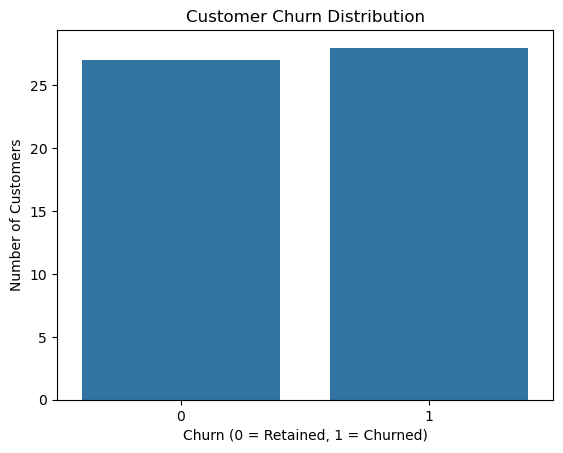

In [45]:
#churn distribution
import matplotlib.pyplot as plt
import seaborn as sns

sns.countplot(
    data=customer_features,
    x='Churn'
)

plt.title('Customer Churn Distribution')
plt.xlabel('Churn (0 = Retained, 1 = Churned)')
plt.ylabel('Number of Customers')

plt.show()

In [46]:
customer_features.to_csv(
    'customer_level_features.csv',
    index=False
)

print("Customer features created successfully!")

Customer features created successfully!
